# Exploratory Data Analysis

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

from utils import *

## Load Data
Load data and select features with an SQL query through the duckdb.

In [2]:
# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'year', 'split', 'patch',
                   'teamname', 'gamelength', 'result', 'kills',
                   'deaths', 'assists', 'towers', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'goldspent'
                   ]

db = 'lol_predictors.duckdb'
df_selected = "df_2014" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include, db)

### Data Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1836 entries, 0 to 1835
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                1836 non-null   str    
 1   league                1836 non-null   str    
 2   year                  1836 non-null   int64  
 3   split                 1680 non-null   str    
 4   patch                 1478 non-null   float64
 5   teamname              1836 non-null   str    
 6   gamelength            1836 non-null   int64  
 7   result                1836 non-null   int64  
 8   kills                 1836 non-null   int64  
 9   deaths                1836 non-null   int64  
 10  assists               1836 non-null   int64  
 11  towers                1836 non-null   float64
 12  dpm                   1836 non-null   float64
 13  damagetakenperminute  1836 non-null   float64
 14  wardskilled           1836 non-null   int64  
 15  totalgold             1836 non-n

In [4]:
df.shape

(1836, 17)

In [5]:
df.describe()

,year,patch,gamelength,result,kills,deaths,assists,towers,dpm,damagetakenperminute,wardskilled,totalgold,goldspent
count,1836.000000,1478.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000
mean,2014.113290,4.091083,2281.938998,0.500000,13.464052,13.486928,31.408497,6.459150,1897.535525,2688.462071,27.109477,61644.996187,54810.416667
std,0.317033,0.129632,518.344662,0.500136,7.458098,7.458904,19.057887,3.412266,467.734221,460.097915,13.230487,15686.132262,15237.440733
min,2014.000000,3.150000,1218.000000,0.000000,0.000000,0.000000,0.000000,0.000000,595.044900,1323.739500,1.000000,23991.000000,20583.000000
25%,2014.000000,4.070000,1920.000000,0.000000,7.000000,8.000000,16.000000,3.000000,1569.569325,2366.829975,17.000000,50453.750000,43937.000000
50%,2014.000000,4.110000,2220.500000,0.500000,13.000000,13.000000,30.000000,7.000000,1880.978450,2675.609300,25.000000,61117.000000,53084.000000
75%,2014.000000,4.140000,2569.000000,1.000000,18.000000,18.000000,45.000000,10.000000,2200.015275,2979.522800,35.000000,71823.750000,63962.750000
max,2015.000000,4.210000,4837.000000,1.000000,51.000000,51.000000,142.000000,11.000000,3802.547300,4663.127400,87.000000,129459.000000,127251.000000


## Data Audit

In [6]:
# Define numerical columns
num_cols = df.select_dtypes(include=["number"]).columns.drop(['year', 'patch', 'result']).tolist()

# Define categorical columns
cat_cols = df.select_dtypes(include=["str"]).columns.drop(['gameid']).tolist()

In [7]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'year', 'split', 'patch', 'teamname', 'gamelength',
       'result', 'kills', 'deaths', 'assists', 'towers', 'dpm',
       'damagetakenperminute', 'wardskilled', 'totalgold', 'goldspent'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                    0
league                    0
year                      0
split                   156
patch                   358
teamname                  0
gamelength                0
result                    0
kills                     0
deaths                    0
assists                   0
towers                    0
dpm                       0
damagetakenperminute      0
wardskilled               0
totalgold                 0
goldspent                 0
dtype: int64


------------- COUNT OF UNIQUE VALUES -------------


gameid                   918
league                     5
year                       2
split                      2
patch                     15
teamname                  81
gamelength               712
result                     2
kills                     41
deaths                    41
assists                   91
towers                    12
dpm                     1836
damagetakenperminute    1835
wardskilled               75
totalgold               1805
goldspent               1780
dtype: int64


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
NA LCS    672
EU LCS    650
NA CS     184
EU CS     174
WLDs      156
Name: count, dtype: int64

 split
Spring    884
Summer    796
Name: count, dtype: int64

 teamname
TSM                       86
Cloud9                    80
Alliance                  78
SK Gaming                 78
Fnatic                    77
Counter Logic Gaming      75
Team Curse                74
Team Coast                73
Millenium                 72
Team ROCCAT               71
Dignitas                  70
Copenhagen Wolves         67
LMQ                       65
Gambit Gaming             64
SUPA HOT CREW             64
Evil Geniuses             63
Curse Academy             44
Ninjas in Pyjamas         39
Reason Gaming             36
XDG Gaming                33
compLexity Gaming         33
H2k-Gaming                29
Team LoLPro               28
SK Gaming Prime           27
Team 8                    23
Gamers2                   22
Royal Club      

In [8]:
count_outliers(df, num_cols)


--------------- COUNT OF OUTLIERS ----------------
gamelength:                32 (1.74%)
kills:                     11 (0.60%)
deaths:                    18 (0.98%)
assists:                    8 (0.44%)
towers:                     0 (0.00%)
dpm:                       21 (1.14%)
damagetakenperminute:      19 (1.03%)
wardskilled:               21 (1.14%)
totalgold:                 15 (0.82%)
goldspent:                 23 (1.25%)


# Data Visualisation

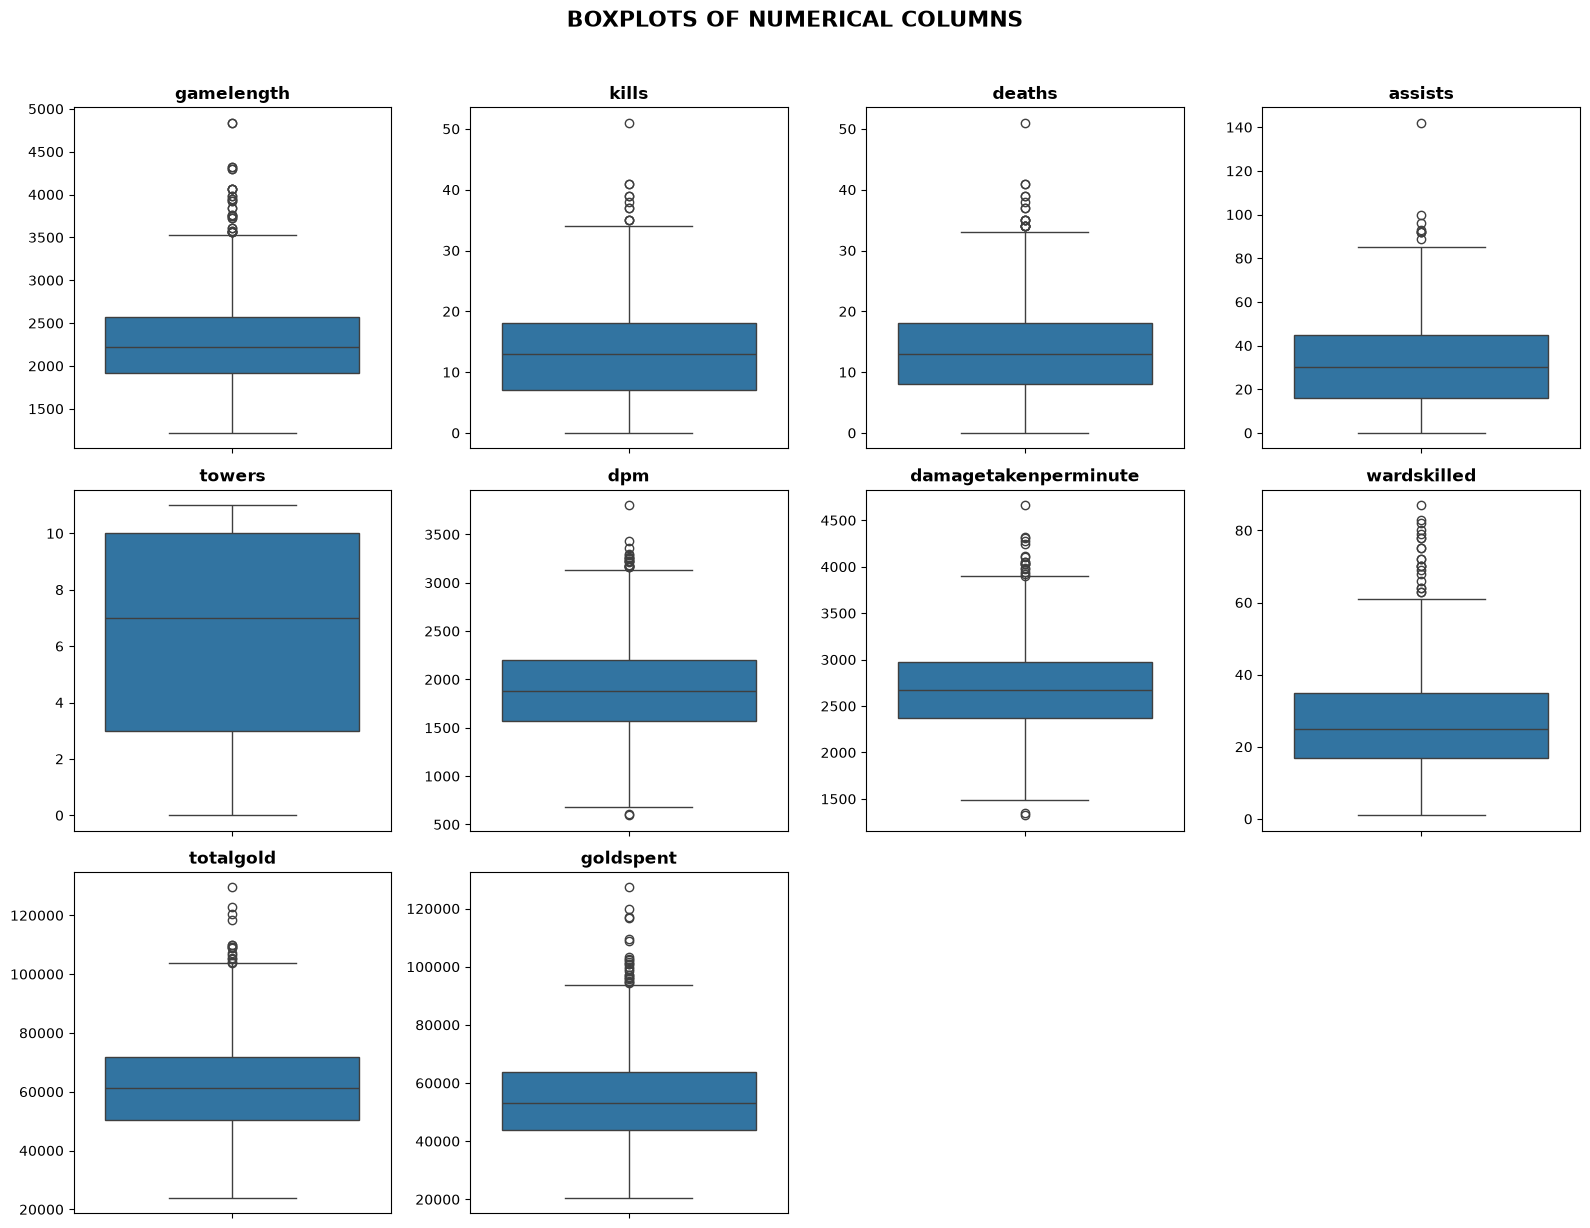

In [9]:
visualize_outliers(df, num_cols)

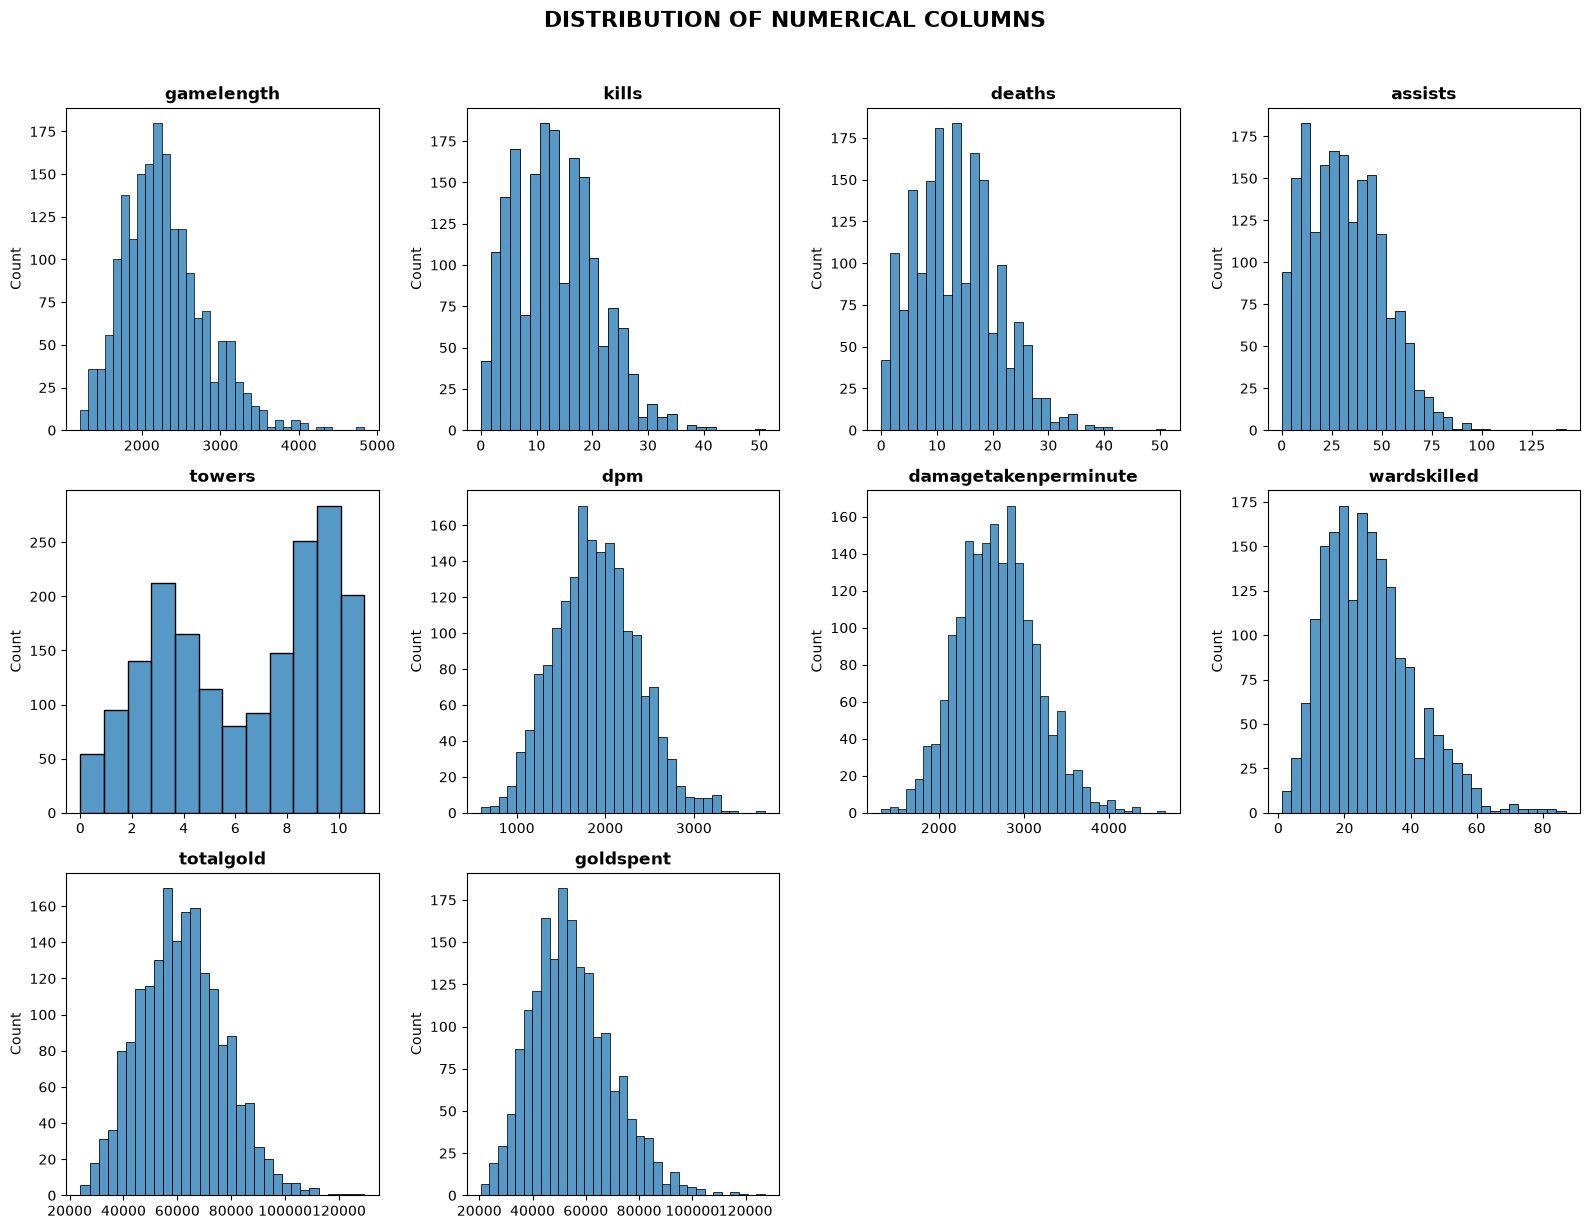

In [10]:
visualize_num_distribution(df, num_cols)

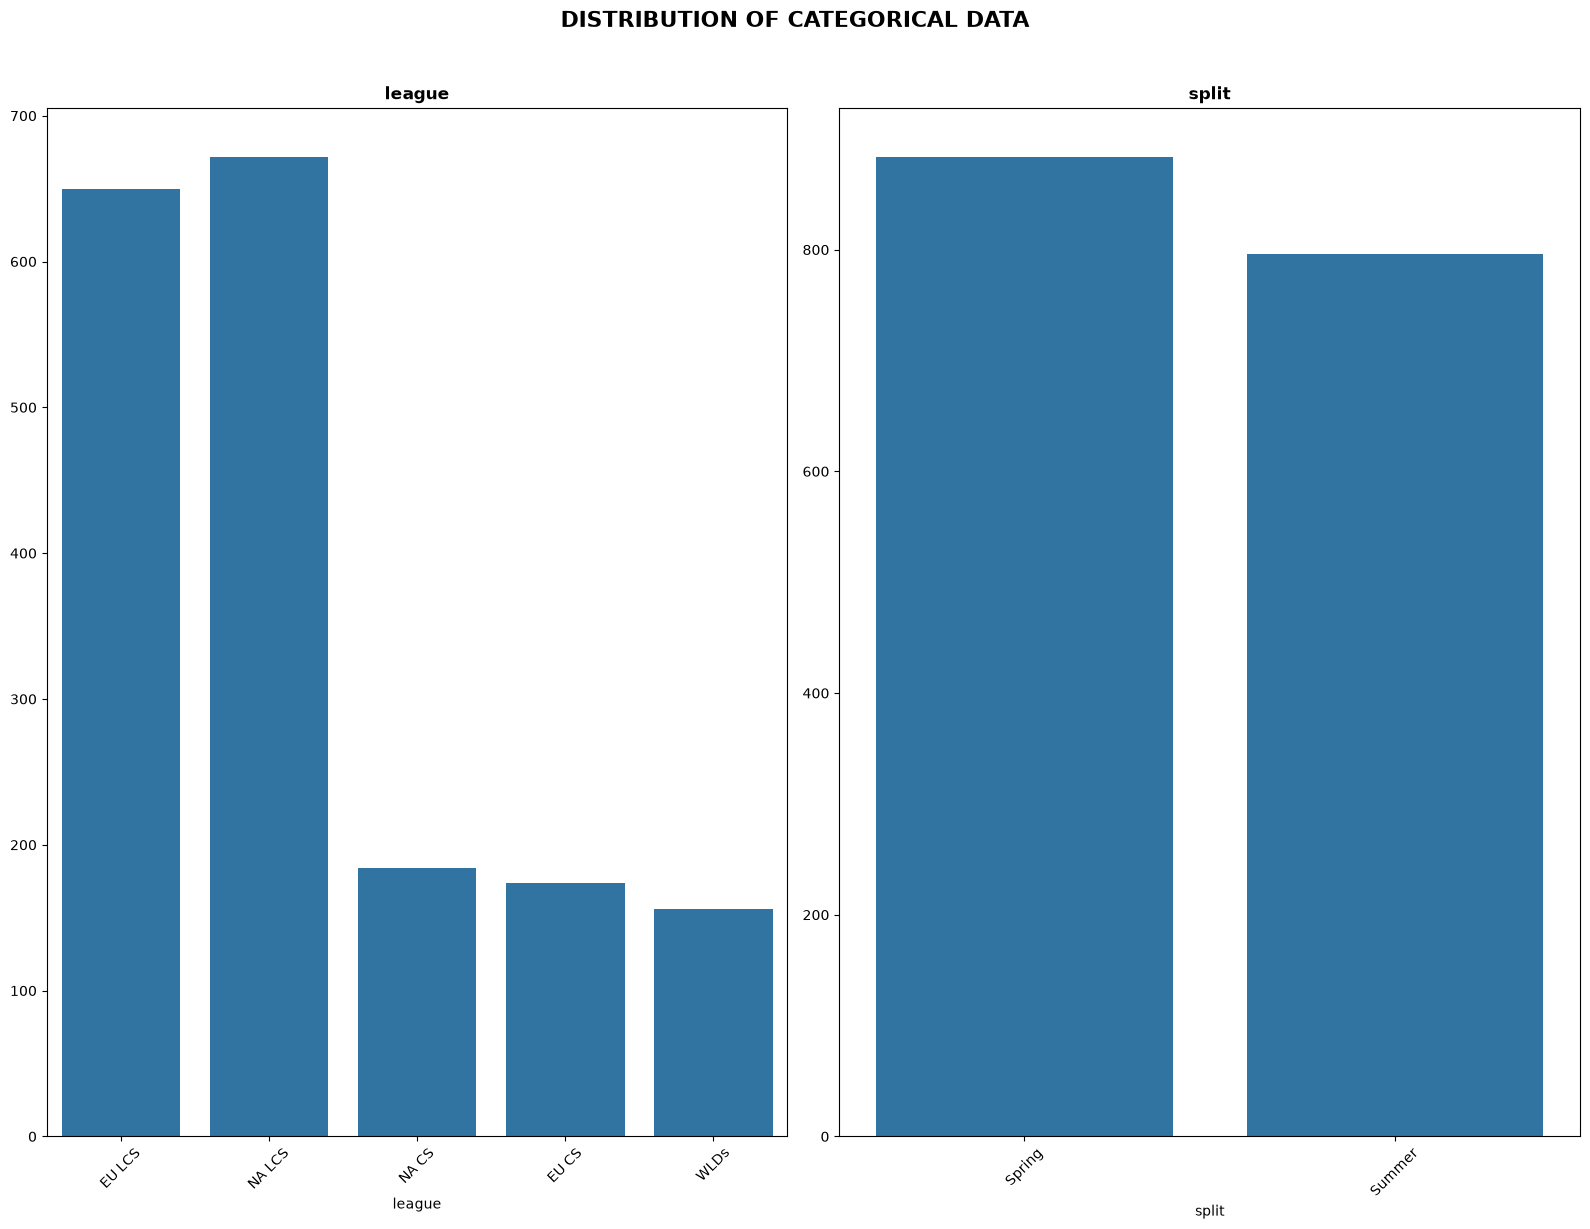

In [11]:
visualize_cat_distribution(df, cat_cols[:2], nrows=1, ncols=2)

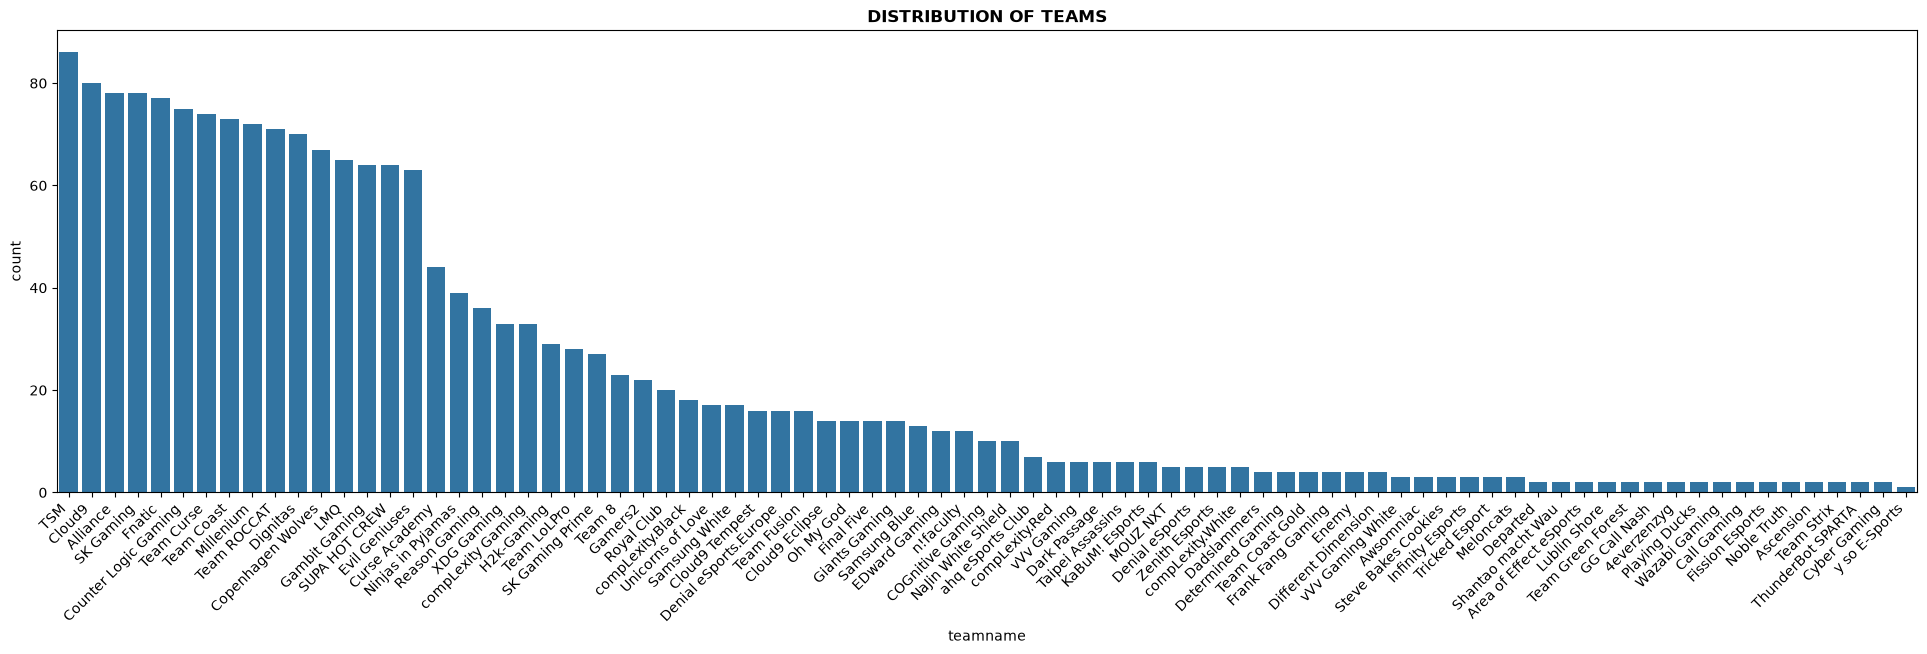

In [12]:
# Separate visualization for team names distribution
team_order = df["teamname"].value_counts().index
plt.figure(figsize=(24, 6))
sns.countplot(data=df, x='teamname', order=team_order)
plt.title('DISTRIBUTION OF TEAMS', fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

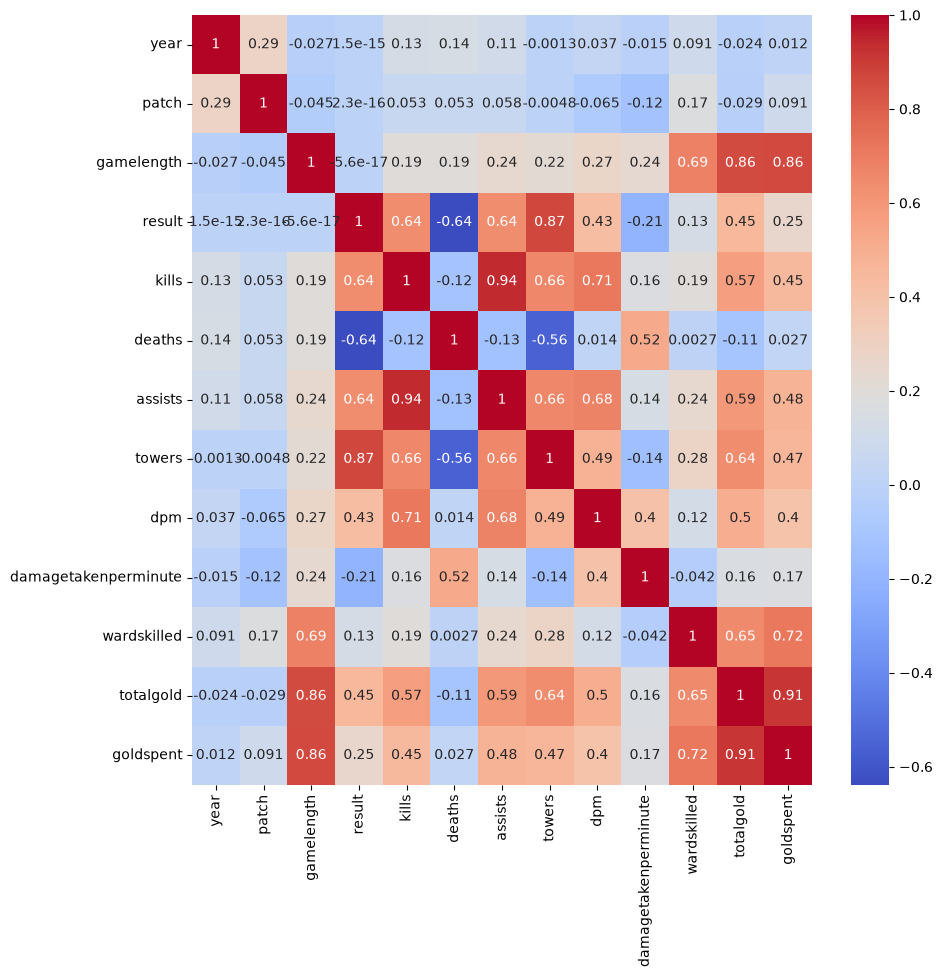

In [13]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True)
plt.show()